# Selection of b1000 sequences and skullstripping

- this can also be executed in the background by the script  *_brainles_skullstripping.py

In [1]:
import pandas as pd
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import matplotlib.pyplot as plt
import nibabel as nib
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt


pd.set_option('display.max_columns', None)
DATA_PATH='/home/bule/berner_daten_analyse/data'
NII_TARGET_PATH = '/home/bule/berner_daten_analyse/data/nifti'

# https://github.com/BrainLesion/preprocessing
# pip install brainles-preprocessing

In [3]:
df=pd.read_csv(os.path.join(DATA_PATH, 'only_2_df.csv'))# each patietn has 2 nfitis
df.head()

,Patient_ID,Study_ID,Sequence_ID,Full_Path_Nifti,join_crit,Path_Nifti,Modality,Date,Shape
0,76813,20170614_4361718,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,/home/bule/berner_daten_analyse/data/nifti/000...,/0000076813/20170614_4361718/ep2d_diff_M128_b0...,/home/bule/berner_daten_analyse/data/nifti/000...,dwi,2017-06-14,"(128, 128, 25, 2)"
1,76813,20170929_4371316,t1_se_tra__1.3.12.2.1107.5.2.41.169589.2017092...,/home/bule/berner_daten_analyse/data/nifti/000...,/0000076813/20170929_4371316/t1_se_tra__1.3.12...,/home/bule/berner_daten_analyse/data/nifti/000...,anatomic,2017-09-29,"(600, 640, 29)"
2,442968,20151109_3835318,ep2d_diff_3scan_trace_p2__1.3.12.2.1107.5.2.30...,/home/bule/berner_daten_analyse/data/nifti/000...,/0000442968/20151109_3835318/ep2d_diff_3scan_t...,/home/bule/berner_daten_analyse/data/nifti/000...,dwi,2015-11-09,"(192, 192, 19, 2)"
3,442968,20151110_3835468,t1_se_r_tra_KM__1.3.12.2.1107.5.2.30.27272.201...,/home/bule/berner_daten_analyse/data/nifti/000...,/0000442968/20151110_3835468/t1_se_r_tra_KM__1...,/home/bule/berner_daten_analyse/data/nifti/000...,anatomic,2015-11-10,"(224, 256, 24)"
4,481858,20121025_3013771,resolve_3scan_trace_tra_176_p2_TRACEW__1.3.12....,/home/bule/berner_daten_analyse/data/nifti/000...,/0000481858/20121025_3013771/resolve_3scan_tra...,/home/bule/berner_daten_analyse/data/nifti/000...,dwi,2012-10-25,"(176, 176, 20, 2)"


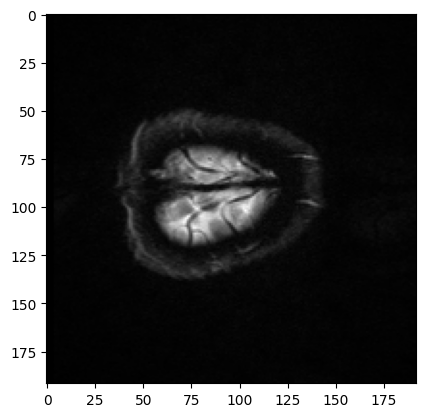

In [4]:
#last one ok?
path='/home/bule/berner_daten_analyse/data/nifti/0082298262/20161224_4200830/ep2d_diff_3scan_trace_p2__1.3.12.2.1107.5.2.30.27272.2016122419201234282284843.0.0.0/ep2d_diff_3scan_trace_p2_1.3.12.2.1107.5.2.30.27272.2016122419201234282284843.0.0.0_ep2d_diff_3scan_trace_p2_20161224191850_2.nii.gz'
dwi = nib.load(path)
plt.imshow(dwi.get_fdata()[:,:,-1,:-1], cmap='gray')

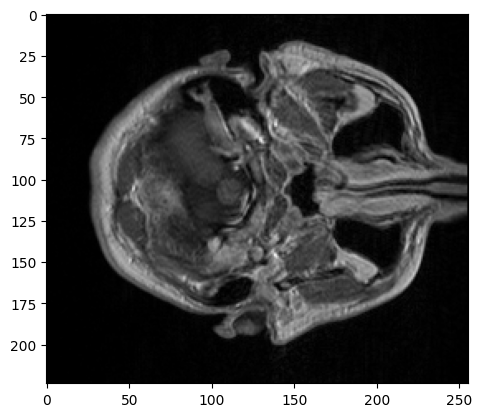

In [5]:
#last one ok?
path='/home/bule/berner_daten_analyse/data/nifti/0082298262/20161224_4200830/t1_se_r_tra_KM__1.3.12.2.1107.5.2.30.27272.2016122419343622034695760.0.0.0/t1_se_r_tra_KM_1.3.12.2.1107.5.2.30.27272.2016122419343622034695760.0.0.0_t1_se_r_tra_KM_20161224191850_14.nii.gz'
dwi = nib.load(path)
plt.imshow(dwi.get_fdata()[:,:,0], cmap='gray')

1. select only b1000 sequence

In [ ]:
import pandas as pd
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from brainles_preprocessing.modality import Modality, CenterModality
from brainles_preprocessing.normalization.percentile_normalizer import (
    PercentileNormalizer,
)
from brainles_preprocessing.preprocessor import Preprocessor


####### docker cont not needed

###################### ADJSUT THE FILES HERE
ANALYSIS_PATH='/home/bule/berner_daten_analyse/data'
NII_TARGET_PATH ='/home/bule/berner_daten_analyse/data/nifti_third_try' #'/home/bule/berner_daten_analyse/data/nifti_second_try'
df=pd.read_csv(os.path.join(ANALYSIS_PATH, 'only2_third_try_df.csv'))# each patietn has 2 nfitis


# THE SHAPE OF THE IMAGES SHOULD BE 3 
filter_index_pos = 3

#### extract b1000 sequence assuming that the last sequence is the b1000 sequence
dfnew = df.copy()
dfnew['sel_b1000']=dfnew['Full_Path_Nifti']


for idx,path in df['Full_Path_Nifti'].items():
    dwi = nib.load(path)
    dwi_shape = dwi.get_fdata().shape

    if not len(dwi_shape) == filter_index_pos + 1:
        print(f"image of patient {path} does not contain {filter_index_pos + 1} dimensions but has shape {dwi_shape}. Skipping this one.")
        continue

    # Take the last sequence and create a new nifti
    b1000_sequence = dwi.get_fdata()[:, :, :, -1]
    new_nifti = nib.Nifti1Image(b1000_sequence, dwi.affine, dwi.header)

    # save the nifti, prepend the potential b1000 sequence
    nifti_folder_path, dwi_file_name = os.path.split(path)

    new_file_path = os.path.join(nifti_folder_path, "b1000-extracted-" + dwi_file_name)
    
    if os.path.exists(new_file_path):
        print(f"File {new_file_path} already exists. Skipping this one.")
        continue
        
    # nib.save(new_nifti, new_file_path)
    
    dfnew.loc[idx,'sel_b1000'] = new_file_path
    
########## create new dataframe with the new paths

dict_paths = {}
for index, row in dfnew.iterrows():
    patient_id = row['Patient_ID']
    if patient_id not in dict_paths:
        dict_paths[patient_id] = {}
    dict_paths[patient_id][row['Modality']] = row['sel_b1000']
dict_paths



- 2 skullstrip

In [ ]:
from pathlib import Path
from brainles_preprocessing.modality import Modality, CenterModality
from brainles_preprocessing.normalization.percentile_normalizer import (
    PercentileNormalizer,
)
from brainles_preprocessing.preprocessor import Preprocessor


count= 0
for patid, mods in dict_paths.items():
    output_folder = Path("/home/bule/berner_daten_analyse/data/nifti_second_try/test/")

    # specify a normalizer
    percentile_normalizer = PercentileNormalizer(
        lower_percentile=0.1,
        upper_percentile=99.9,
        lower_limit=0,
        upper_limit=1,
    )

    # define center and moving modalities
    center = CenterModality(
        modality_name="t1",
        input_path=Path(mods['t1']),
        normalizer=percentile_normalizer,
        # specify the output paths for the raw and normalized images of each step - here only for atlas registered and brain extraction
        raw_skull_output_path=output_folder/f"{patid}/raw_skull_dir/t1_skull_raw.nii.gz",
        raw_bet_output_path=output_folder/f"{patid}/raw_bet_dir/t1_bet_raw.nii.gz",
        raw_defaced_output_path=output_folder/f"{patid}/raw_defaced_dir/t1_defaced_raw.nii.gz",
        normalized_skull_output_path=output_folder/f"{patid}/norm_skull_dir/t1_skull_normalized.nii.gz",
        normalized_bet_output_path=output_folder/f"{patid}/norm_bet_dir/t1_bet_normalized.nii.gz",
        normalized_defaced_output_path=output_folder/f"{patid}/norm_defaced_dir/t1_defaced_normalized.nii.gz",
        # specify output paths for the brain extraction and defacing masks
        bet_mask_output_path=output_folder/f"{patid}/masks/t1_bet_mask.nii.gz",
        defacing_mask_output_path=output_folder/f"{patid}/masks/t1_defacing_mask.nii.gz",
    )


    moving_modalities = [
        Modality(
            modality_name="dwi",
            input_path=Path(mods['dwi']),
            normalizer=percentile_normalizer,
            # specify the output paths for the raw and normalized images of each step - here only for atlas registered and brain extraction
            raw_skull_output_path=output_folder/f"{patid}/raw_skull_dir/dwi_skull_raw.nii.gz",
            raw_bet_output_path=output_folder/f"{patid}/raw_bet_dir/dwi_bet_raw.nii.gz",
            raw_defaced_output_path=output_folder/f"{patid}/raw_defaced_dir/dwi_defaced_raw.nii.gz",
            normalized_skull_output_path=output_folder/f"{patid}/norm_skull_dir/dwi_skull_normalized.nii.gz",
            normalized_bet_output_path=output_folder/f"{patid}/norm_bet_dir/dwi_bet_normalized.nii.gz",
            normalized_defaced_output_path=output_folder/f"{patid}/norm_defaced_dir/dwi_defaced_normalized.nii.gz",
        )
    ]

    # instantiate and run the preprocessor using defaults for registration/ brain extraction/ defacing backends
    preprocessor = Preprocessor(
        center_modality=center,
        moving_modalities=moving_modalities,
    )

    # preprocessor.run()
    # count+=1
    # if count == 3:
    #     break
